---
# Executed by scripts/export_gw_examples.py; the docs build shows the stored outputs.
execute:
  skip: true
---
# 8. Marginalizing over the amplitudes

This page was generated from [`notebooks/gw/08_ringdown_marginalized.py`](https://github.com/Potatoasad/astroinfer/blob/main/notebooks/gw/08_ringdown_marginalized.py), a marimo notebook. Sliders and other controls are shown at their default values. To change them, run the notebook with `uv run marimo edit notebooks/gw/08_ringdown_marginalized.py`.

The model of notebook 7 has eight parameters: the mass and spin of the remnant, an amplitude
scale per mode, and two quadratures per mode. The quadratures enter the signal linearly, and
both their prior and the noise are Gaussian, so they can be integrated out of the likelihood
exactly. ringdown does this by default. This notebook builds the same marginalization from
astroinfer pieces: a measurement process that knows which of its parameters are linear, a
marginal likelihood over the others, and the Gaussian posterior of the linear parameters,
which gives them back after sampling.

The data and the model are those of notebook 7, GW150914 in Hanford and Livingston. The
notebook needs the `ringdown` dependency group:

```bash
uv run --group ringdown marimo edit notebooks/gw/08_ringdown_marginalized.py
```

In [1]:
import sys
from pathlib import Path

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "scripts" / "marimo_docs_shim.py").is_file())
sys.path[:0] = [str(ROOT / "notebooks/gw"), str(ROOT / "scripts")]

import marimo_docs_shim
marimo_docs_shim.set_notebook_dir(ROOT / "notebooks/gw")
sys.modules["marimo"] = marimo_docs_shim

# marimo shows a figure only when a cell returns it. Stop Jupyter from also showing every
# figure a cell creates, and close them once the cell has run.
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import flush_figures
get_ipython().run_line_magic("matplotlib", "inline")
try:
    get_ipython().events.unregister("post_execute", flush_figures)
except ValueError:
    pass
get_ipython().events.register("post_execute", lambda: plt.close("all"))

# Show astroinfer objects with their HTML display (as Jupyter does), not the short markdown one.
get_ipython().display_formatter.formatters["text/markdown"].enabled = False
# Open every object display, so readers see the contents without having to click.
import astroinfer.display
astroinfer.display.set_options(expanded=True)


In [2]:
import jax

jax.config.update("jax_enable_x64", True)

import time
from dataclasses import dataclass
from typing import Any

import astroinfer as ai
import gwpy.timeseries  # noqa: F401  (ringdown fetches open data through gwpy)
import jax.numpy as jnp
import marimo as mo
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pandas as pd
import ringdown as rd
import scipy.linalg
import scipy.stats
from astroinfer import MeasurementProcess, batched_method, parameter, parameter_dataclass
from astroinfer.display import html_value
from jax.flatten_util import ravel_pytree
from jax.scipy.linalg import solve_triangular
from numpyro.distributions import constraints
from ringdown.model import chi_factors
from ringdown.utils.swsh import calc_YpYc, construct_sYlm

# Importing gwpy changes matplotlib's defaults and replaces its default Axes class; restore
# both, so that the plots look like those of the other notebooks.
mpl.rcdefaults()
mpl.projections.register_projection(mpl.axes.Axes)

POSTERIOR, PRIOR, DATA, TRUTH, EXTRA = "#418FC5", "#eb6834", "#1baf7a", "#17243D", "#6250d6"

STRAIN_UNIT = 1e-21  # strain is measured in units of 1e-21 throughout
RD_MODES = [(1, -2, 2, 2, 0), (1, -2, 2, 2, 1)]
MODES = ("220", "221")
IFOS = ["H1", "L1"]
T0 = 1126259462.4083147
SKY = dict(ra=1.95, dec=-1.27, psi=0.82)

# ringdown's Kerr spectrum and angular factors, as in notebook 7.
KERR_F = jnp.array([rd.qnms.KerrMode(m).coefficients[0] for m in RD_MODES])
KERR_G = jnp.array([rd.qnms.KerrMode(m).coefficients[1] for m in RD_MODES])
_swsh = construct_sYlm(-2, np.array([m[2] for m in RD_MODES]),
                       np.array([m[3] for m in RD_MODES]))
Y_PLUS, Y_CROSS, _ = (jnp.asarray(y) for y in calc_YpYc(-1.0, _swsh))

## The marginal likelihood

Split the parameters into nonlinear ones $\theta$ (here the remnant) and linear ones $a$
(the quadratures, $K$ numbers in all). The signal is $h = M(\theta)\,a$, where the *design
matrix* $M(\theta)$ has one column per linear parameter, the noise is Gaussian with
covariance $C = LL^\top$, and the prior of the linear parameters is
$a\sim\mathcal N(0, \mathrm{diag}\,s^2)$, with prior scales $s$. Writing $a = s\odot b$ with
$b\sim\mathcal N(0, I)$, and whitening,

$$
W = L^{-1}M\,\mathrm{diag}(s),\qquad z = L^{-1}d,\qquad RR^\top = I + W^\top W,\qquad
u = R^{-1}W^\top z,
$$

the integral over $b$ is Gaussian and gives

$$
\log\mathcal L(d\mid\theta, s) = -\tfrac12|z|^2 + \tfrac12|u|^2 - \sum_j\log R_{jj}
  - \sum_k\log L_{kk} - \tfrac n2\log 2\pi .
$$

The linear parameters given $\theta$, $s$ and the data are Gaussian too:

$$
b\mid d,\theta,s \sim \mathcal N\!\left(R^{-\top}u,\ (RR^\top)^{-1}\right).
$$

This is the formula in ringdown's `make_model`. Only $K\times K$ matrices are factored, and
the noise enters through $L^{-1}$, which the measurement process already applies.

## The interface

Three classes carry this, none of them specific to ringdowns.

`LinearGaussianMeasurement` is a measurement process whose signal is linear in part of
$\theta$, with Gaussian noise. A subclass declares `nonlinear_type` and `linear_type`, the
parameter types of the two parts, and writes

| method | what it returns |
|---|---|
| `signal_single(theta)` | the signal for one full $\theta$, an array of the data's shape |
| `combine(nonlinear, linear)` | the full $\theta$ from its two parts |
| `whiten(x)`, `color(z)`, `log_det_noise()` | $L^{-1}x$, $Lz$ and $\sum_k\log L_{kk}$ |
| `to_array(d)`, `from_array(x)` | the data as an array, and back |

From these the base class gives `sample_single` and `logpdf_single`, so it is an ordinary
measurement process, and `design_matrix_single(nonlinear, template)`, the design matrix
computed as the Jacobian of the signal with respect to the linear parameters, packed into a
vector by `jax.flatten_util.ravel_pytree`. Since the signal is linear, the Jacobian is the
design matrix exactly, and its columns are in the order of the packed vector by
construction. A subclass can override it with an analytic design matrix.

`measurement.marginalized()` returns a `MarginalLikelihood`, the conditional distribution
$\mathcal L(d\mid\theta, s)$ with the linear parameters integrated out. Its conditions are
`theta`, of the nonlinear type, and `scale`, the prior standard deviations, given as an object
of the linear type: `Quadratures(ax=a_scale, ay=a_scale)` gives every quadrature of a mode
that mode's amplitude scale.

`measurement.linear_posterior()` returns a `LinearPosterior`, the conditional distribution
$p(a\mid d, \theta, s)$, whose output is an object of the linear type. Both are
`ConditionalDistribution`s, so `ai.sample` puts them in a NumPyro model, and astroinfer
batches them: one call to `sample` draws the linear parameters for every posterior draw of
$\theta$.

In [3]:
def linear_solve(measurement, d, theta, scale):
    """The quantities of the marginal likelihood for one ``d``, ``theta`` and ``scale``.

    Returns ``(z, R, u, s, unravel)``: the whitened data, the Cholesky factor of
    ``I + W^T W``, ``R^{-1} W^T z``, the packed prior scales and the function that unpacks a
    vector of linear parameters into an object of the linear type.
    """
    s, unravel = ravel_pytree(scale)
    M = measurement.design_matrix_single(theta, scale) * s
    W = jax.vmap(measurement.whiten, in_axes=-1, out_axes=-1)(M).reshape(-1, s.size)
    z = measurement.whiten(measurement.to_array(d)).ravel()
    R = jnp.linalg.cholesky(jnp.eye(s.size) + W.T @ W)
    u = solve_triangular(R, W.T @ z, lower=True)
    return z, R, u, s, unravel

In [4]:
@dataclass(eq=False)
class MarginalLikelihood(ai.ConditionalDistribution):
    """L(d | theta, s): a linear Gaussian measurement with its linear parameters integrated out."""

    measurement: Any

    density_latex = r"\mathcal{L}"
    _output_symbol = "d"

    def _output_type(self):
        return self.measurement.data_type

    def _condition_type(self):
        return {"theta": self.measurement.nonlinear_type, "scale": self.measurement.linear_type}

    def logpdf_single(self, d, theta, scale):
        z, R, u, s, _ = linear_solve(self.measurement, d, theta, scale)
        return (-0.5 * z @ z + 0.5 * u @ u - jnp.sum(jnp.log(jnp.diag(R)))
                - self.measurement.log_det_noise() - 0.5 * z.size * jnp.log(2 * jnp.pi))

    def sample_single(self, theta, scale, key):
        key_a, key_d = jax.random.split(key)
        s, unravel = ravel_pytree(scale)
        a = unravel(s * jax.random.normal(key_a, s.shape))
        return self.measurement.sample_single(self.measurement.combine(theta, a), key_d)

    def _display_equations(self):
        return [r"\mathcal{L}(d\mid\theta, s) = \int \mathcal{L}(d\mid\theta, a)\,"
                r"\mathcal{N}\!\left(a;\, 0, \mathrm{diag}\,s^2\right)\,da"]

    def _display_config(self):
        return {"measurement": html_value(self.measurement._repr_html_())}

In [5]:
@dataclass(eq=False)
class LinearPosterior(ai.ConditionalDistribution):
    """p(a | d, theta, s): the Gaussian posterior of the linear parameters."""

    measurement: Any

    _output_symbol = "a"

    def _output_type(self):
        return self.measurement.linear_type

    def _condition_type(self):
        return {"d": self.measurement.data_type, "theta": self.measurement.nonlinear_type,
                "scale": self.measurement.linear_type}

    def sample_single(self, d, theta, scale, key):
        _, R, u, s, unravel = linear_solve(self.measurement, d, theta, scale)
        eps = jax.random.normal(key, s.shape)
        return unravel(s * solve_triangular(R.T, u + eps, lower=False))

    def logpdf_single(self, a, d, theta, scale):
        _, R, u, s, _ = linear_solve(self.measurement, d, theta, scale)
        b = ravel_pytree(a)[0] / s
        r = R.T @ b - u
        return (-0.5 * r @ r + jnp.sum(jnp.log(jnp.diag(R))) - jnp.sum(jnp.log(s))
                - 0.5 * s.size * jnp.log(2 * jnp.pi))

    def _display_equations(self):
        return [r"p(a\mid d, \theta, s) \propto \mathcal{L}(d\mid\theta, a)\,"
                r"\mathcal{N}\!\left(a;\, 0, \mathrm{diag}\,s^2\right)"]

    def _display_config(self):
        return {"measurement": type(self.measurement).__name__}

In [6]:
@dataclass(eq=False)
class LinearGaussianMeasurement(MeasurementProcess):
    """A measurement d = h(theta, a) + n, with h linear in a and Gaussian noise n.

    Subclasses set ``parameter_type``, ``data_type``, ``nonlinear_type`` and ``linear_type``,
    and write ``signal_single``, ``combine``, ``whiten``, ``color``, ``log_det_noise``,
    ``to_array`` and ``from_array``.
    """

    nonlinear_type = None
    linear_type = None

    def design_matrix_single(self, theta, template):
        """``(*data shape, K)``: d signal / d a, with a packed like ``template``."""
        flat, unravel = ravel_pytree(template)

        def signal(x):
            return self.signal_single(self.combine(theta, unravel(x)))

        return jax.jacfwd(signal)(jnp.zeros_like(flat))

    def sample_single(self, theta, key):
        h = self.signal_single(theta)
        return self.from_array(h + self.color(jax.random.normal(key, h.shape)))

    def logpdf_single(self, d, theta):
        w = self.whiten(self.to_array(d) - self.signal_single(theta))
        return -0.5 * jnp.sum(w**2) - self.log_det_noise() - 0.5 * w.size * jnp.log(2 * jnp.pi)

    def marginalized(self):
        """The likelihood with the linear parameters integrated out, L(d | theta, s)."""
        return MarginalLikelihood(self)

    def linear_posterior(self):
        """The Gaussian posterior of the linear parameters, p(a | d, theta, s)."""
        return LinearPosterior(self)

## The Kerr ringdown as a linear Gaussian measurement

The types and the detector configuration are those of notebook 7. The measurement process
now says which of its parameters are linear: the remnant is nonlinear and the quadratures are
linear. It writes the signal once, as in notebook 7, and leaves the design matrix to the base
class.

In [7]:
def kerr_qnms(M, chi):
    """Frequencies [Hz] and damping rates [1/s] of the modes, from ringdown's Kerr fits."""
    f0 = 1.0 / (M * rd.qnms.T_MSUN)
    return f0 * chi_factors(chi, KERR_F), f0 * chi_factors(chi, KERR_G)

In [8]:
@parameter_dataclass(name="Remnant", latex=r"\theta_f")
class Remnant:
    M: float = parameter(name="Detector-frame mass [M_sun]", latex="M",
                         support=constraints.positive)
    chi: float = parameter(name="Dimensionless spin", latex=r"\chi",
                           support=constraints.interval(0.0, 0.99))

    @batched_method
    def qnms(self):
        """``(f, gamma)``, each with one entry per mode."""
        return kerr_qnms(self.M, self.chi)

In [9]:
@parameter_dataclass(name="Quadratures", latex="a")
class Quadratures:
    ax: float = parameter(name="Cosine quadrature [1e-21]", latex="a_x", index=("mode",),
                          index_latex=("n",))
    ay: float = parameter(name="Sine quadrature [1e-21]", latex="a_y", index=("mode",),
                          index_latex=("n",))

    @batched_method
    def amplitude(self):
        return jnp.hypot(self.ax, self.ay)

In [10]:
@parameter_dataclass(name="Kerr ringdown", latex=r"\theta")
class KerrRingdown:
    remnant: Remnant
    modes: Quadratures

In [11]:
@parameter_dataclass(name="Network strain", latex="d")
class NetworkStrain:
    h: float = parameter(name="Strain [1e-21]", latex="d", index=("ifo", "time"),
                         index_latex=("I", "k"))

In [12]:
@parameter_dataclass(name="Detector network", latex="D")
class DetectorConfig:
    t: float = parameter(name="Time since the start of the segment [s]", latex="t",
                         index=("ifo", "time"), index_latex=("I", "k"))
    fp: float = parameter(name="Plus antenna pattern", latex="F_+", index=("ifo",),
                          index_latex=("I",))
    fc: float = parameter(name="Cross antenna pattern", latex=r"F_\times", index=("ifo",),
                          index_latex=("I",))
    cholesky: float = parameter(name="Cholesky factor of the noise covariance", latex="L",
                                index=("ifo", "time", "time"), index_latex=("I", "k", "k'"))

    @classmethod
    def from_ringdown(cls, fit, scale=STRAIN_UNIT):
        """The analysis times, antenna patterns and noise of a conditioned ringdown ``Fit``."""
        ifos = fit.ifos
        return cls(
            t=jnp.stack([fit.analysis_times[i] - float(fit.start_times[i]) for i in ifos]),
            fp=jnp.array([fit.antenna_patterns[i][0] for i in ifos]),
            fc=jnp.array([fit.antenna_patterns[i][1] for i in ifos]),
            cholesky=jnp.stack([fit.cholesky_factors[i] for i in ifos]) / scale,
        )

    @property
    def shape(self):
        return self.fp.shape[-1], self.t.shape[-1]

    def project(self, hp, hc):
        return self.fp[:, None] * hp + self.fc[:, None] * hc

    def whiten(self, x):
        return jax.vmap(lambda L, y: solve_triangular(L, y, lower=True))(self.cholesky, x)

    def color(self, z):
        return jnp.einsum("ikl,il->ik", self.cholesky, z)

    def log_det(self):
        return jnp.sum(jnp.log(jnp.diagonal(self.cholesky, axis1=-2, axis2=-1)))

In [13]:
@dataclass(eq=False)
class KerrNetwork(LinearGaussianMeasurement):
    detectors: DetectorConfig
    ifos: tuple = ("H1", "L1")

    display_name = "Kerr ringdown in a detector network"
    parameter_type = KerrRingdown
    data_type = NetworkStrain
    nonlinear_type = Remnant
    linear_type = Quadratures

    def combine(self, remnant, modes):
        return KerrRingdown(remnant=remnant, modes=modes)

    def signal_single(self, theta):
        t = self.detectors.t
        f, gamma = kerr_qnms(theta.remnant.M, theta.remnant.chi)
        phase = 2 * jnp.pi * f[:, None, None] * t
        decay = jnp.exp(-gamma[:, None, None] * t)
        ax, ay = theta.modes.ax[:, None, None], theta.modes.ay[:, None, None]
        yp, yc = Y_PLUS[:, None, None], Y_CROSS[:, None, None]
        hp = jnp.sum(yp * decay * (ax * jnp.cos(phase) + ay * jnp.sin(phase)), axis=0)
        hc = jnp.sum(yc * decay * (ax * jnp.sin(phase) - ay * jnp.cos(phase)), axis=0)
        return self.detectors.project(hp, hc)

    def whiten(self, x):
        return self.detectors.whiten(x)

    def color(self, z):
        return self.detectors.color(z)

    def log_det_noise(self):
        return self.detectors.log_det()

    def to_array(self, d):
        return d.h

    def from_array(self, x):
        return NetworkStrain(h=x)

    def _display_config(self):
        return {"detectors": html_value(self.detectors._repr_html_()),
                "names": ", ".join(self.ifos)}

## The data

The data are prepared as in notebook 7, with ringdown's settings for GW150914.

In [14]:
fit = rd.Fit(modes=RD_MODES)
fit.load_data(ifos=IFOS, channel="GWOSC", start=1126259447, end=1126259479,
              sample_rate=16384, cache=True)
fit.set_target(T0, duration=0.2, **SKY)
fit.condition_data(ds=8, f_min=20)
fit.compute_acfs(f_min=20)

network = KerrNetwork(DetectorConfig.from_ringdown(fit), ifos=tuple(fit.ifos))
data = NetworkStrain(h=jnp.stack([np.asarray(fit.analysis_data[i]) for i in fit.ifos])
                     / STRAIN_UNIT)
marginal = network.marginalized()
amplitudes = network.linear_posterior()
mo.hstack([marginal, amplitudes], justify="start", gap=2, align="start")

MarginalLikelihood(measurement=KerrNetwork(detectors=DetectorConfig(batch_shape=(), t=(2, 410), fp=(2,), fc=(2,), cholesky=(2, 410, 410)), ifos=('H1', 'L1')))

measurement,KerrNetwork


## Checks

Two checks on a test point, $M = 70\,M_\odot$, $\chi = 0.7$, with prior scales of 2. The
design matrix times the packed quadratures should reproduce the signal, since the signal is
linear in them. The largest difference, in units of $10^{-21}$:

In [15]:
test_remnant = Remnant(M=70.0, chi=0.7)
test_scale = Quadratures(ax=jnp.full(2, 2.0), ay=jnp.full(2, 2.0))
_a = Quadratures(ax=jnp.array([1.0, -0.5]), ay=jnp.array([0.3, 2.0]))
_M = network.design_matrix_single(test_remnant, test_scale)
_h = network.signal_single(KerrRingdown(remnant=test_remnant, modes=_a))
_M.shape, float(jnp.max(jnp.abs(_M @ ravel_pytree(_a)[0] - _h)))

((2, 410, 4), 4.440892098500626e-16)

The design matrix has one column per quadrature, four in all, for each of the
$2\times410$ samples, and it reproduces the signal to rounding error.

The marginal likelihood should equal the density of the data under the Gaussian with the
linear parameters integrated out by brute force, $d\sim\mathcal N(0,\ C + M\,\mathrm{diag}(s^2)\,M^\top)$,
with the $820\times820$ covariance of both detectors written out:

In [16]:
_s, _ = ravel_pytree(test_scale)
_M = np.asarray(network.design_matrix_single(test_remnant, test_scale)).reshape(-1, _s.size)
_C = scipy.linalg.block_diag(*[np.asarray(L @ L.T) for L in network.detectors.cholesky])
_dense = scipy.stats.multivariate_normal(np.zeros(len(_C)), _C + _M @ np.diag(_s**2) @ _M.T)
float(marginal.logpdf(data, theta=test_remnant, scale=test_scale)), float(_dense.logpdf(np.asarray(data.h).ravel()))

(-701.4682389622014, -701.4682389614604)

The two agree to $7\times10^{-10}$, the rounding error of the dense density.

## The model

The model samples the amplitude scales and the remnant, and observes the data through the
marginal likelihood. The quadratures are no longer a site of the model:

In [17]:
def per_mode(distribution):
    return distribution.expand([len(MODES)]).to_event(1)

remnant_prior = Remnant.distribution(M=dist.Uniform(40.0, 140.0), chi=dist.Uniform(0.0, 0.99))

def model(data):
    a_scale = ai.sample("a_scale", per_mode(dist.Uniform(0.0, 50.0)))
    remnant = ai.sample("remnant", remnant_prior)
    ai.sample("d", marginal, theta=remnant, scale=Quadratures(ax=a_scale, ay=a_scale),
              obs=data)

ai.model_graph(model, data)

Graph('Graph of model', nodes=['root:a_scale', 'root:remnant', 'root:d'], edges=[('root:a_scale', 'root:d'), ('root:remnant', 'root:d')])

In [18]:
_start = time.perf_counter()
posterior = ai.infer(model, data, seed=0, num_warmup=1000, num_samples=4000, summary=False)
sampling_time = time.perf_counter() - _start
posterior.summary(["remnant.M", "remnant.chi", "a_scale"], expand=True)

,mean,sd,5.0%,95.0%,ess,r_hat
remnant.M,72.234280,8.027129,58.304521,84.567539,1334.978882,0.999983
remnant.chi,0.680853,0.161298,0.447589,0.918584,1233.204611,1.000021
a_scale[0],5.219433,6.998625,0.307393,12.783871,837.219718,0.999831
a_scale[1],5.261632,7.016339,0.006296,12.475066,1349.621750,0.999852


In [19]:
round(sampling_time, 1)

19.3

NUTS takes about 20 s on a laptop CPU, including compilation, against about 38 s for the full
model of notebook 7 on the same machine, and has no divergent transitions. The effective
sample sizes of $M$ and $\chi$ are 1335 and 1233 in 4000 draws, against 1065 and 927 for the
full model, which also samples the four quadratures. (The 90% intervals in this table are
NumPyro's highest-density intervals; the table below gives equal-tailed ones.)

## The amplitudes after sampling

`amplitudes.sample` draws the quadratures from their Gaussian posterior. The posterior draws
of the remnant have batch shape (chain, draw), the data have none, and the scales are built
from the drawn amplitude scales, so astroinfer gives one draw of the quadratures per
posterior draw:

In [20]:
_a_scale = posterior.theta.a_scale
quadratures = amplitudes.sample(d=data, theta=posterior.theta.remnant,
                                scale=Quadratures(ax=_a_scale, ay=_a_scale), key=1)
full = KerrRingdown(remnant=posterior.theta.remnant, modes=quadratures)
full

KerrRingdown(batch_shape=(1, 4000), remnant=Remnant(batch_shape=(1, 4000), M=(1, 4000), chi=(1, 4000)), modes=Quadratures(batch_shape=(1, 4000), ax=(1, 4000, 2), ay=(1, 4000, 2)))

`full` holds the posterior of all the parameters, as the sampler of notebook 7 gave it. It is
compared below with ringdown's fit of the same data, run with the same seed as in notebook 7:

In [21]:
fit.update_model(a_scale_max=5e-20, m_min=40.0, m_max=140.0, cosi=-1)
fit.run(prng=0)
ringdown_posterior = {
    name: np.asarray(fit.result.posterior[name]).reshape(
        -1, *np.shape(fit.result.posterior[name])[2:])
    for name in ["m", "chi", "f", "g", "a"]
}
ringdown_posterior["a"] = ringdown_posterior["a"] / STRAIN_UNIT

In [22]:
def describe(x):
    x = np.asarray(x).ravel()
    return {"mean": x.mean(), "sd": x.std(), "5%": np.percentile(x, 5),
            "95%": np.percentile(x, 95)}

_r = ringdown_posterior
_f, _gamma = full.remnant.qnms()
_A = full.modes.amplitude()
_pairs = {"M": (full.remnant.M, _r["m"]), "chi": (full.remnant.chi, _r["chi"])}
for _i, _mode in enumerate(MODES):
    _pairs[f"f_{_mode} [Hz]"] = (_f[..., _i], _r["f"][:, _i])
    _pairs[f"gamma_{_mode} [1/s]"] = (_gamma[..., _i], _r["g"][:, _i])
    _pairs[f"A_{_mode} [1e-21]"] = (_A[..., _i], _r["a"][:, _i])
pd.DataFrame(
    {(_name, _code): describe(_x)
     for _name, (_ours, _theirs) in _pairs.items()
     for _code, _x in [("astroinfer, marginalized", _ours), ("ringdown", _theirs)]}
).T.round(3)

mean       sd       5%      95%
M               astroinfer, marginalized   72.234    8.026   59.138   85.594
                ringdown                   72.469    8.947   58.562   85.781
chi             astroinfer, marginalized    0.681    0.161    0.349    0.875
                ringdown                    0.678    0.173    0.316    0.882
f_220 [Hz]      astroinfer, marginalized  241.309    8.872  225.997  254.941
                ringdown                  240.943    8.812  225.456  254.169
gamma_220 [1/s] astroinfer, marginalized  227.320   41.216  163.365  299.662
                ringdown                  226.807   43.899  160.705  302.765
A_220 [1e-21]   astroinfer, marginalized    1.769    0.416    1.123    2.485
                ringdown                    1.769    0.449    1.098    2.528
f_221 [Hz]      astroinfer, marginalized  235.891   10.238  217.545  251.581
                ringdown                  235.490   10.295  217.235  250.668
gamma_221 [1/s] astroinfer, marginalized  688.168  127.539  492.019  914.354
                ringdown                  686.731  135.874  484.007  924.851
A_221 [1e-21]   astroinfer, marginalized    1.993    0.821    0.628    3.370
                ringdown                    2.010    0.841    0.698    3.430

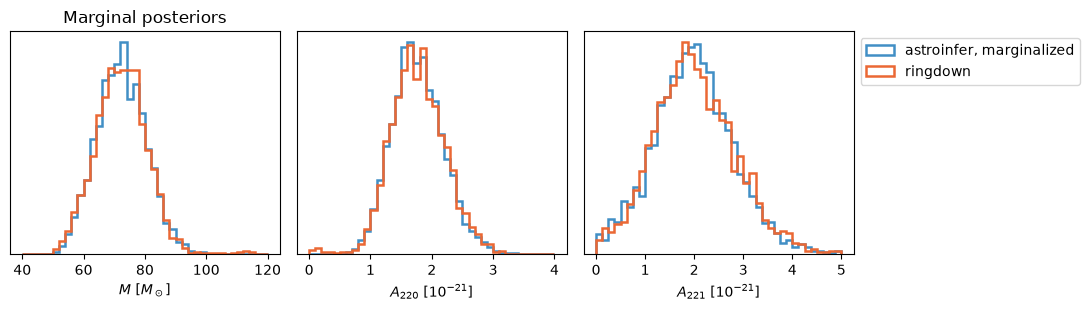

In [23]:
_A = np.asarray(full.modes.amplitude()).reshape(-1, 2)
_fig, _axes = plt.subplots(1, 3, figsize=(11.0, 3.2))
for _ax, (_ours, _theirs, _bins, _label) in zip(_axes, [
    (np.asarray(full.remnant.M).ravel(), ringdown_posterior["m"], np.linspace(40, 120, 41),
     r"$M\ [M_\odot]$"),
    (_A[:, 0], ringdown_posterior["a"][:, 0], np.linspace(0, 4, 41), r"$A_{220}\ [10^{-21}]$"),
    (_A[:, 1], ringdown_posterior["a"][:, 1], np.linspace(0, 5, 41), r"$A_{221}\ [10^{-21}]$"),
]):
    _ax.hist(_ours, bins=_bins, density=True, histtype="step", color=POSTERIOR,
             linewidth=1.8, label="astroinfer, marginalized")
    _ax.hist(_theirs, bins=_bins, density=True, histtype="step", color=PRIOR,
             linewidth=1.8, label="ringdown")
    _ax.set(xlabel=_label, yticks=[])
_axes[0].set_title("Marginal posteriors")
_axes[2].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
_fig.tight_layout()
_fig

The marginalized posterior agrees with ringdown's. The means of $M$ are 72.2 and
$72.5\,M_\odot$, with standard deviations of 8.0 and 8.9, and the means of $\chi$ are 0.681
and 0.678, with standard deviations of 0.161 and 0.173. The amplitude of the fundamental mode
has a mean of 1.77 in both, and that of the overtone 1.99 and 2.01. The full model of notebook
7 gave $M = 71.9\pm8.0\,M_\odot$ and $\chi = 0.675\pm0.166$; the three posteriors differ by
about as much as runs of one code with different seeds.